In [1]:
import pandas as pd
import numpy as np



In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, mean_squared_error, r2_score

from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [3]:
# Load dataset
df = pd.read_csv('customer_analytics.csv')

# Inspect basic dataset details
print("Dataset Shape:", df.shape)
print("\n--- Column Info ---")
print(df.info())

# Display first 5 rows
df.head()

Dataset Shape: (5000, 13)

--- Column Info ---
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               5000 non-null   str    
 1   Age                       5000 non-null   int64  
 2   Gender                    5000 non-null   str    
 3   Account_Age_Days          5000 non-null   int64  
 4   Total_Orders              5000 non-null   int64  
 5   Average_Order_Value       5000 non-null   float64
 6   Total_Spend               5000 non-null   float64
 7   Days_Since_Last_Purchase  5000 non-null   int64  
 8   App_Sessions_Last_30D     5000 non-null   int64  
 9   Support_Tickets_Raised    5000 non-null   int64  
 10  Satisfaction_Score        5000 non-null   int64  
 11  Churn_Target              5000 non-null   int64  
 12  CLV_Next_Year_Target      5000 non-null   float64
dtypes: float64(3), int64(8), st

,Customer_ID,Age,Gender,Account_Age_Days,Total_Orders,Average_Order_Value,Total_Spend,Days_Since_Last_Purchase,App_Sessions_Last_30D,Support_Tickets_Raised,Satisfaction_Score,Churn_Target,CLV_Next_Year_Target
0,CUST-10000,56,Female,237,10,36.71,367.10,159,13,2,4,1,86.70
1,CUST-10001,69,Male,1274,20,51.93,1038.60,13,13,1,4,0,662.76
2,CUST-10002,46,Female,1315,10,99.14,991.40,56,17,0,1,1,394.22
3,CUST-10003,32,Male,439,11,68.26,750.86,240,14,0,5,0,923.58
4,CUST-10004,60,Female,360,16,89.57,1433.12,275,7,0,4,0,1661.05


In [4]:
# K-Means Clustering to generating 'Cluster' column
features_seg = ['Account_Age_Days', 'Total_Orders', 'Average_Order_Value', 'Total_Spend']
X_seg = df[features_seg]

scaler = StandardScaler()
X_seg_scaled = scaler.fit_transform(X_seg)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_seg_scaled)


In [5]:
# Column list in vertical format
for col in df.columns:
    print(col)

Customer_ID
Age
Gender
Account_Age_Days
Total_Orders
Average_Order_Value
Total_Spend
Days_Since_Last_Purchase
App_Sessions_Last_30D
Support_Tickets_Raised
Satisfaction_Score
Churn_Target
CLV_Next_Year_Target
Cluster


In [6]:
# Selected features and target for Churn Prediction
features_churn = [
    'Age', 'Account_Age_Days', 'Total_Orders', 'Average_Order_Value', 
    'Total_Spend', 'Days_Since_Last_Purchase', 'App_Sessions_Last_30D', 
    'Support_Tickets_Raised', 'Satisfaction_Score', 'Cluster'
]

X_churn = df[features_churn]
y_churn = df['Churn_Target']

# Train-Test Split (80% Train, 20% Test)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_churn, y_churn, test_size=0.20, random_state=42, stratify=y_churn
)

# Train Random Forest Model
churn_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
churn_model.fit(X_train_c, y_train_c)

# Predict & Display Evaluation Report
y_pred_churn = churn_model.predict(X_test_c)

print(" Churn Prediction Performance ---")
print(classification_report(y_test_c, y_pred_churn))

 Churn Prediction Performance ---
              precision    recall  f1-score   support

           0       0.62      0.77      0.69       575
           1       0.53      0.36      0.43       425

    accuracy                           0.59      1000
   macro avg       0.58      0.56      0.56      1000
weighted avg       0.58      0.59      0.58      1000



In [7]:
# Selected features and target for CLV Forecasting
features_clv = [
    'Account_Age_Days', 'Total_Orders', 'Average_Order_Value', 
    'Total_Spend', 'App_Sessions_Last_30D', 'Satisfaction_Score', 'Cluster'
]

X_clv = df[features_clv]
y_clv = df['CLV_Next_Year_Target']

# Train-Test Split (80% Train, 20% Test)
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_clv, y_clv, test_size=0.20, random_state=42
)

# Train Linear Regression Model
clv_model = LinearRegression()
clv_model.fit(X_train_l, y_train_l)

# Predict & Evaluate Performance
y_pred_clv = clv_model.predict(X_test_l)
r2 = r2_score(y_test_l, y_pred_clv)
rmse = np.sqrt(mean_squared_error(y_test_l, y_pred_clv))

print(" CLV Forecasting Performance ---")
print(f"R2 Score: {r2:.4f}")
print(f"RMSE: ${rmse:.2f}")

 CLV Forecasting Performance ---
R2 Score: 0.4618
RMSE: $405.45


In [8]:
# Master Function: Customer 360 Analytics Output
def get_customer_360_analytics(customer_id):
    customer_data = df[df['Customer_ID'] == customer_id]
    if customer_data.empty:
        return f"Customer ID '{customer_id}' not found!"
    
    # Extract prediction data
    cluster_id = customer_data['Cluster'].values[0]
    churn_flag = customer_data['Churn_Target'].values[0]
    predicted_clv = customer_data['CLV_Next_Year_Target'].values[0]
    
    churn_status = "High Risk of Churn" if churn_flag == 1 else "Low Risk (Active)"
    
    return {
        "Customer ID": customer_id,
        "Assigned Cluster": int(cluster_id),
        "Churn Prediction": churn_status,
        "Forecasted Next Year CLV": f"${predicted_clv:,.2f}"
    }

# Sample test run
print("--- Master Engine Output Sample ---")
print(get_customer_360_analytics("CUST-10002"))

--- Master Engine Output Sample ---
{'Customer ID': 'CUST-10002', 'Assigned Cluster': 3, 'Churn Prediction': 'High Risk of Churn', 'Forecasted Next Year CLV': '$394.22'}


In [9]:
import pandas as pd


df = pd.read_csv('customer_analytics.csv')


def get_customer_360_analytics(customer_id):
    customer_data = df[df['Customer_ID'] == customer_id]
    
    if customer_data.empty:
        return f"Customer ID '{customer_id}' not found!"
    
    cluster_id = int(customer_data['Cluster'].values[0]) if 'Cluster' in customer_data else "N/A"
    churn_flag = customer_data['Churn_Target'].values[0] if 'Churn_Target' in customer_data else 0
    predicted_clv = customer_data['CLV_Next_Year_Target'].values[0] if 'CLV_Next_Year_Target' in customer_data else 0
    
    churn_status = "High Risk of Churn" if churn_flag == 1 else "Low Risk of Churn"
    
    return {
        "Customer ID": customer_id,
        "Assigned Cluster": cluster_id,
        "Churn Prediction": churn_status,
        "Forecasted Next Year CLV": f"${predicted_clv:,.2f}"
    }


print("--- Master Engine Output Sample ---")
print(get_customer_360_analytics("CUST-10002"))

--- Master Engine Output Sample ---
{'Customer ID': 'CUST-10002', 'Assigned Cluster': 'N/A', 'Churn Prediction': 'High Risk of Churn', 'Forecasted Next Year CLV': '$394.22'}


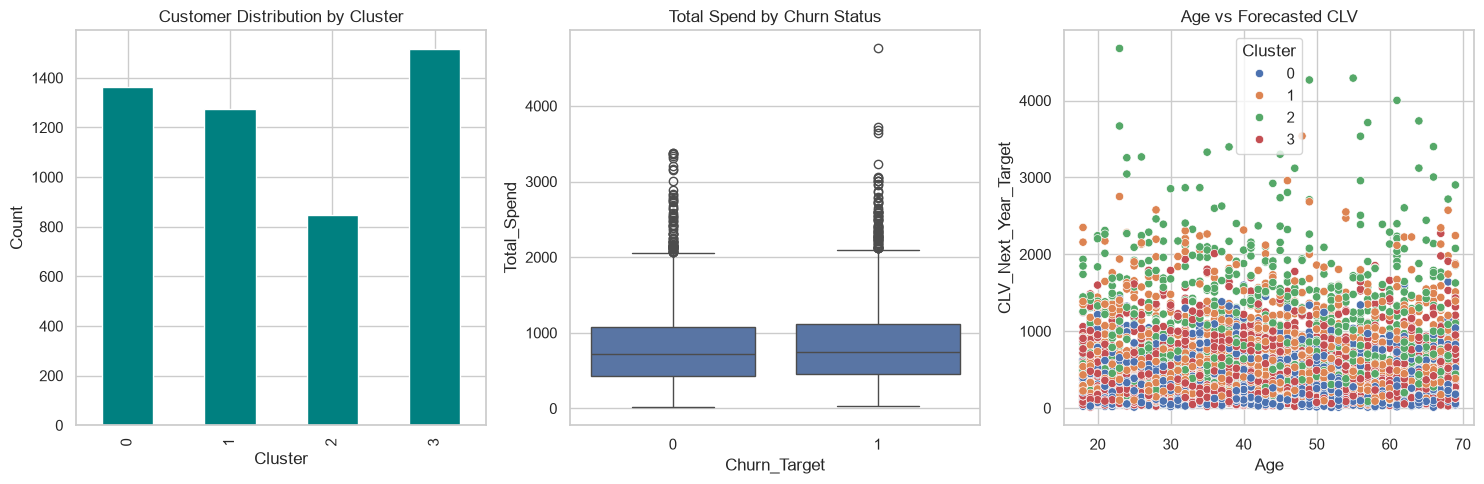

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


df = pd.read_csv('customer_analytics.csv')


features_seg = ['Account_Age_Days', 'Total_Orders', 'Average_Order_Value']
X_seg = df[features_seg]

scaler = StandardScaler()
X_seg_scaled = scaler.fit_transform(X_seg)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_seg_scaled)
plt.figure(figsize=(15, 5))

# 1. Cluster Distribution
plt.subplot(1, 3, 1)
df['Cluster'].value_counts().sort_index().plot(kind='bar', color='teal')
plt.title('Customer Distribution by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Count')

# 2. Churn Target vs Total Spend
plt.subplot(1, 3, 2)
sns.boxplot(x='Churn_Target', y='Total_Spend', data=df)
plt.title('Total Spend by Churn Status')

# 3. Age vs Forecasted CLV
plt.subplot(1, 3, 3)
sns.scatterplot(x='Age', y='CLV_Next_Year_Target', hue='Cluster', data=df, palette='deep')
plt.title('Age vs Forecasted CLV')

plt.tight_layout()
plt.show()